### Dylan Renard
### Applied Machine Learning JHU
### Homework 12
### Professor Alhassan
### April 20th, 2026

## HW Assignment 12: Applied Machine Learning @JHU

#### Credit card fraud costs about 1% of their revenue to the banks, an amount which customers (us) eventually pay. Let's find those anomalies which might reveal a fraud. Download the popular credit card dataset from kaggle.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")

#### Q1: Explore the dataset, list the number fo rows and columns, check sanity, and examine the features (e.g. with histograms or plots).

Shape: (284807, 31)
Columns: Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

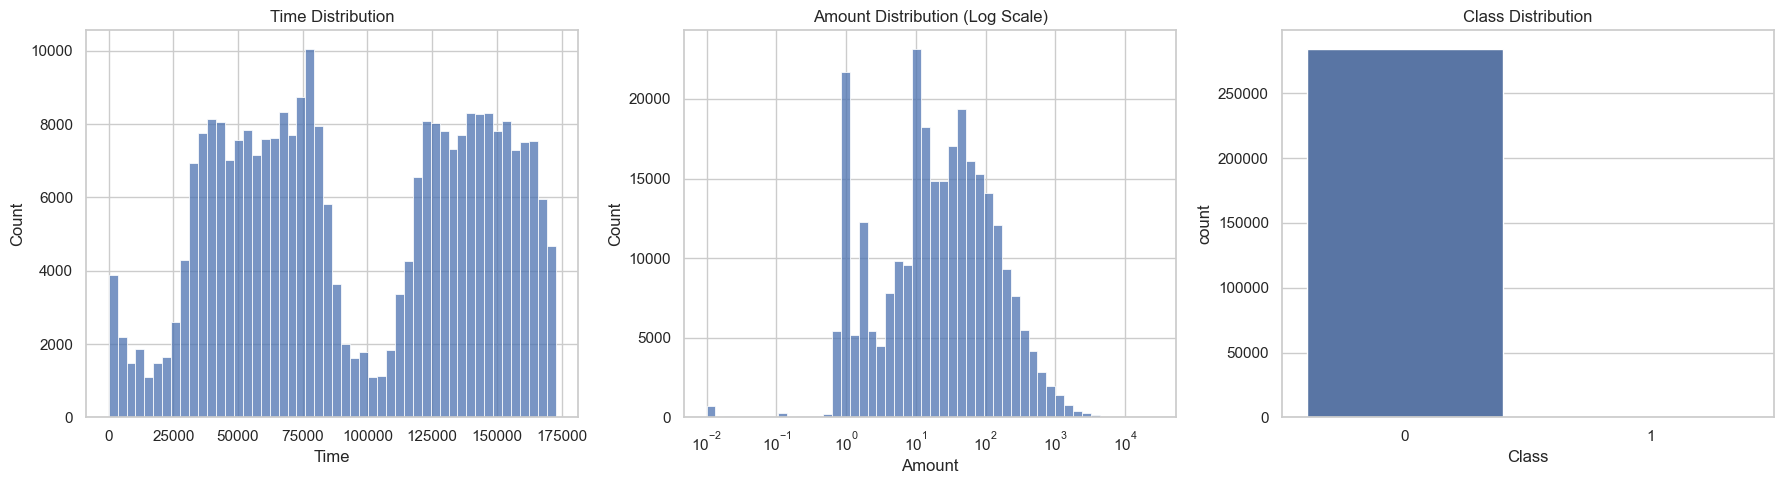

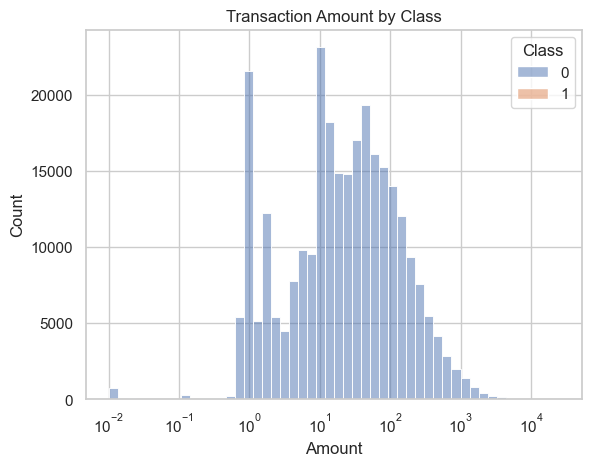

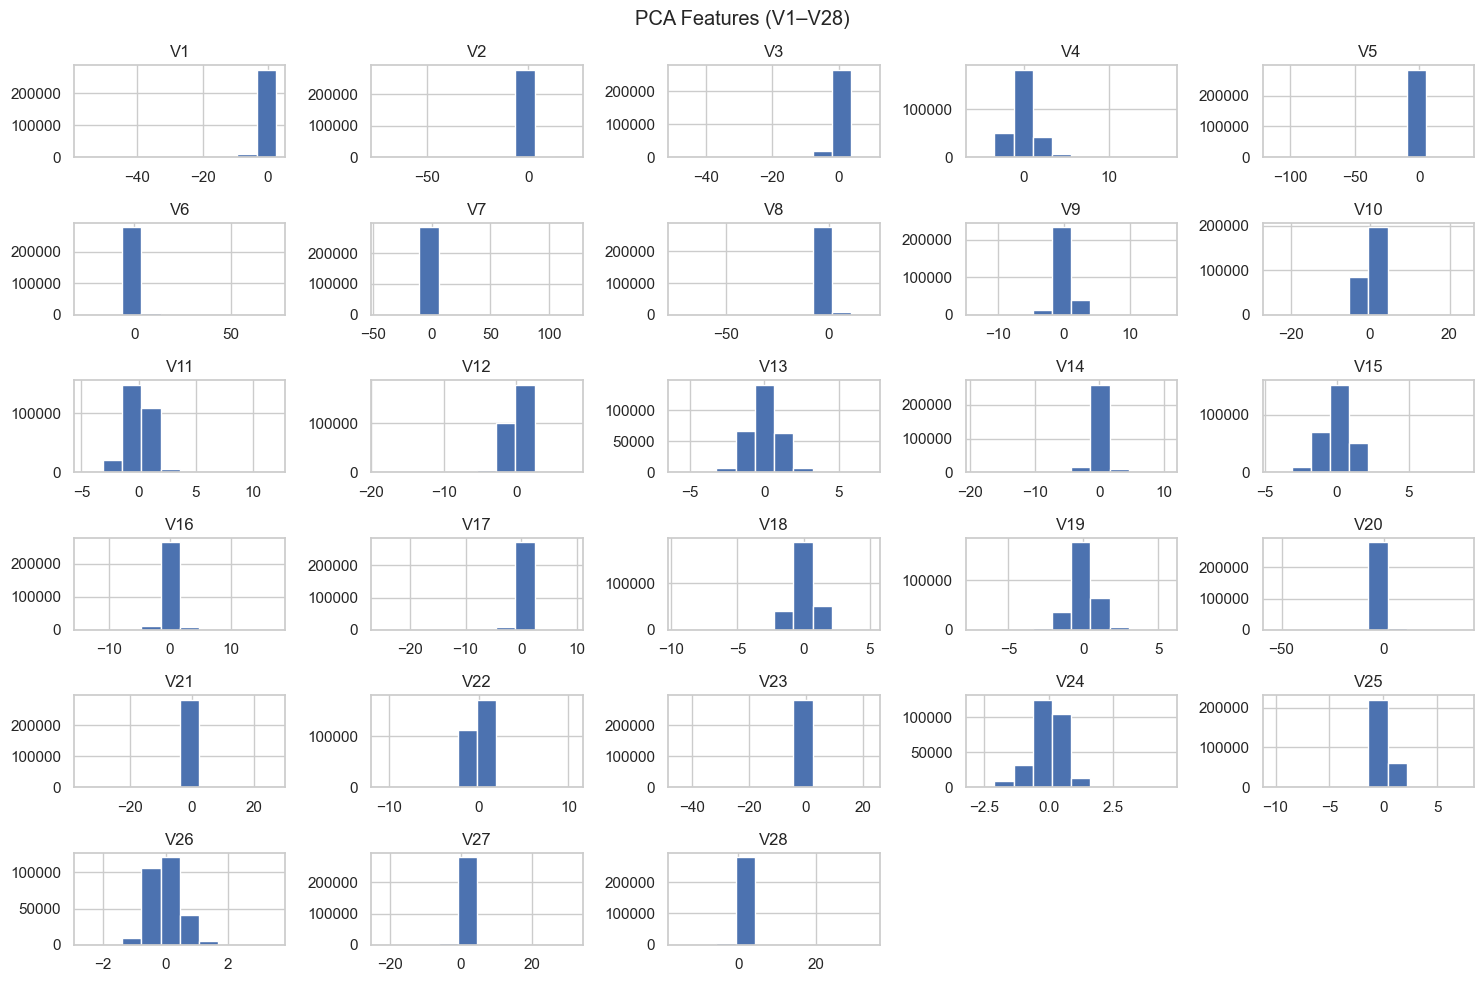

In [2]:
# Basic exploration
print("Shape:", df.shape)
print("Columns:", df.columns)

display(df.head())
df.info()

print("\nMissing values:\n", df.isnull().sum())
print("\nSummary statistics:\n", df.describe())

# Set plotting style
sns.set(style="whitegrid")

# Key feature plots (clean + informative)
fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.histplot(df['Time'], bins=50, ax=axes[0])
axes[0].set_title("Time Distribution")

sns.histplot(df['Amount'], bins=50, log_scale=True, ax=axes[1])
axes[1].set_title("Amount Distribution (Log Scale)")

sns.countplot(x='Class', data=df, ax=axes[2])
axes[2].set_title("Class Distribution")

plt.tight_layout()
plt.show()

# Amount vs Class (NO KDE → stable)
sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=True
)
plt.title("Transaction Amount by Class")
plt.show()

# PCA features grouped (not overwhelming)
pca_cols = [col for col in df.columns if col.startswith('V')]

df[pca_cols].hist(figsize=(15,10))
plt.suptitle("PCA Features (V1–V28)")
plt.tight_layout()
plt.show()

#### Q1 Interpretation: 
The dataset contains 284,807 rows and 31 columns, consisting of 30 numerical features and one target variable (Class) indicating whether a transaction is fraudulent. A preliminary sanity check confirmed that there are no missing values, and all features are numeric (float64 for predictors and int64 for the target), making the dataset clean and ready for analysis without additional preprocessing for missing data.

The majority of the features (V1–V28) are the result of a principal component analysis (PCA) transformation applied to the original dataset. These features are centered around zero and exhibit varying spreads, as observed in the histograms. While this transformation ensures normalization and reduces multicollinearity, it also limits interpretability, as the original meaning of the variables is not directly accessible.

Exploratory analysis using histograms revealed several important patterns. The transaction amount feature is highly right-skewed, with most transactions occurring at low values and a small number of very large transactions forming a long tail. A logarithmic transformation helps stabilize this distribution but does not fully separate fraudulent from non-fraudulent transactions, indicating that amount alone is not a strong predictor.

The time feature shows a non-uniform distribution across the dataset, suggesting temporal variation in transaction frequency. This may reflect real-world behavioral cycles and indicates potential value in temporal feature engineering.

A critical finding from the dataset exploration is the extreme class imbalance. Fraudulent transactions represent only about 0.17% of the data, while the vast majority are non-fraudulent. This imbalance was confirmed through class distribution plots and has major implications for model development, as standard accuracy metrics would be misleading.

Overall, the dataset is clean, numerically well-structured, and suitable for machine learning. However, the exploratory analysis highlights key challenges, including severe class imbalance, skewed feature distributions, and limited interpretability of PCA-derived features. These factors must be addressed in subsequent modeling steps to build an effective fraud detection system.

#### Q2: Check the class balance, choose an evaluation metric, and justify the choice.

The dataset is highly imbalanced, with only 492 fraudulent transactions out of 284807 total observations, approximately 0.17 percent, while the remaining transactions belong to the non fraudulent class. This extreme imbalance implies that the minority class is underrepresented by several orders of magnitude, making it difficult for models to learn meaningful patterns associated with fraud. Additionally, exploratory analysis showed that features such as transaction amount are highly skewed and overlapping between classes, indicating that fraud detection cannot rely on simple thresholds and requires careful evaluation of model performance.

Given this imbalance, accuracy is not an appropriate evaluation metric. A model that predicts all transactions as non fraudulent would achieve over 99 percent accuracy while completely failing to detect fraud, making accuracy misleading in this context. Instead, evaluation must focus on performance with respect to the minority class.

Precision and recall are more appropriate metrics for this task. Recall measures the proportion of actual fraudulent transactions correctly identified and is especially important because false negatives, or missed fraud, carry significant real world cost. Precision measures the proportion of predicted fraud cases that are actually fraudulent, reflecting the burden of false positives. Since there is an inherent tradeoff between these two metrics, relying on either alone is insufficient.

Therefore, the F1 score is selected as the primary evaluation metric, as it provides a balanced measure of precision and recall. This is particularly suitable for imbalanced classification problems where both detecting fraud and limiting false alarms are important. While alternative metrics such as the precision recall area under the curve could also be used, F1 score is preferred here because it provides a single interpretable value for comparing models at a fixed decision threshold, which aligns with the evaluation setup used in this assignment. In contrast, PR AUC evaluates performance across all thresholds and is more appropriate when threshold tuning is the primary objective.

Overall, the F1 score ensures that model performance reflects meaningful fraud detection capability rather than majority class dominance, making it an appropriate metric for this highly imbalanced classification task.

#### Q3: Check if you need normalization or standardization, and justify. Complete pre-processing.

Based on the observations from Q1, additional normalization or standardization is not required for the majority of features, as variables V1–V28 are PCA-transformed components that are already centered around zero with unit-like variance. This implies that these features have effectively been standardized during prior preprocessing and are suitable for algorithms that are sensitive to feature scaling, such as neural networks and support vector machines.

However, the Amount feature is highly skewed and exists on a different scale compared to the PCA components. To address this, a log transformation (for example log1p) is applied to reduce skewness and compress extreme values. This helps stabilize gradient-based learning and prevents large magnitude transactions from disproportionately influencing model updates. In contrast, tree-based models such as Random Forest are invariant to feature scaling, meaning this transformation primarily benefits distance-based and neural network models rather than all models uniformly.

The Time feature does not require scaling but may have limited predictive value in its raw form, as it represents elapsed time rather than a meaningful behavioral signal. While feature engineering such as extracting periodic patterns could improve its utility, it is retained as-is for consistency across models.

As part of preprocessing, the dataset is split into training and testing sets using stratified sampling to preserve the original class imbalance. Importantly, resampling techniques such as SMOTE are applied only to the training data after the split to avoid data leakage. This ensures that synthetic samples do not influence the test set and maintains a fair evaluation of model generalization.

Overall, preprocessing includes applying a log transformation to the Amount feature, performing a stratified train-test split, and addressing class imbalance through SMOTE on the training set only, while leaving PCA-transformed features unchanged due to their already standardized nature.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# -----------------------------
# Baseline preprocessing
# -----------------------------
# V1–V28 are already PCA-transformed / standardized
# Amount is highly skewed, so apply log transform
df["Amount_log"] = np.log1p(df["Amount"])

# Drop original Amount after transformation
df_baseline = df.drop(columns=["Amount"])

# -----------------------------
# Separate features and target
# -----------------------------
X = df_baseline.drop(columns=["Class"])
y = df_baseline["Class"]

# -----------------------------
# 50-50 stratified train-test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    stratify=y,
    random_state=42
)

print("Baseline training set shape:", X_train.shape)
print("Baseline test set shape:", X_test.shape)

print("\nBaseline class distribution in training set:")
print(y_train.value_counts())

print("\nBaseline class distribution in test set:")
print(y_test.value_counts())

# -----------------------------
# SMOTE version (training data only)
# -----------------------------
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nSMOTE training set shape:", X_train_smote.shape)
print("\nClass distribution in SMOTE training set:")
print(pd.Series(y_train_smote).value_counts())

# -----------------------------
# Optional: package datasets clearly
# -----------------------------
baseline_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test
}

smote_data = {
    "X_train": X_train_smote,
    "X_test": X_test,   # test set remains untouched
    "y_train": y_train_smote,
    "y_test": y_test
}



Baseline training set shape: (142403, 30)
Baseline test set shape: (142404, 30)

Baseline class distribution in training set:
Class
0    142157
1       246
Name: count, dtype: int64

Baseline class distribution in test set:
Class
0    142158
1       246
Name: count, dtype: int64

SMOTE training set shape: (284314, 30)

Class distribution in SMOTE training set:
Class
0    142157
1    142157
Name: count, dtype: int64


#### Q4: Split the dataset 50-50 for training and testing. Then, without any tree pruning or regularization, run classifiers of the following types (reporting each one's classification performance):
* SVC
* DecisionTreeClassifier
* MLPClassifier
* RandomForest

In [4]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# --------------------------------------------------
# Q4: Baseline models on imbalanced data (no SMOTE)
# --------------------------------------------------
# Assumes you already created:
# X_train, X_test, y_train, y_test
# from the 50-50 stratified split in Q3

models = {
    "SVC": SVC(kernel="linear"),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
    "MLPClassifier": MLPClassifier(max_iter=200, random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42, n_jobs=-1)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*20} {name} {'='*20}")
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred, digits=4)
    
    results[name] = {
        "confusion_matrix": cm,
        "classification_report": report
    }
    
    print("Confusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(report)


==================== SVC ====================
Confusion Matrix:
[[142122     36]
 [   181     65]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9987    0.9997    0.9992    142158
           1     0.6436    0.2642    0.3746       246

    accuracy                         0.9985    142404
   macro avg     0.8211    0.6320    0.6869    142404
weighted avg     0.9981    0.9985    0.9982    142404


==================== DecisionTreeClassifier ====================
Confusion Matrix:
[[142093     65]
 [    60    186]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9995    0.9996    142158
           1     0.7410    0.7561    0.7485       246

    accuracy                         0.9991    142404
   macro avg     0.8703    0.8778    0.8740    142404
weighted avg     0.9991    0.9991    0.9991    142404


==================== MLPClassifier ====================
Confusion Matrix:
[[14

#### Q4 Results Interpretation: 
The baseline models demonstrate varying levels of performance on the imbalanced dataset. While overall accuracy is high across all models due to the dominance of the majority class, performance on the minority class differs significantly. The SVC model performs poorly in detecting fraudulent transactions, achieving a recall of only 0.26, indicating that most fraud cases are missed. This is because SVC optimizes for maximum margin, and in highly imbalanced settings, the decision boundary is dominated by the majority class, leading to minimal representation of minority class regions.

In contrast, the MLP classifier improves recall to approximately 0.70, though at the cost of lower precision, resulting in more false positives. This reflects the flexibility of neural networks, which can learn more complex decision boundaries, but are still influenced by class imbalance through the loss function, which is dominated by the majority class.

The Decision Tree classifier provides a better balance between precision and recall, achieving an F1-score of approximately 0.75 for the minority class. This is because decision trees partition the feature space in a non-linear and rule-based manner, allowing them to isolate minority class regions more effectively. However, without pruning, they remain prone to overfitting and instability.

The Random Forest model performs the best overall, with high precision (0.97) and strong recall (0.74), resulting in the highest F1-score among the models. This improved performance is due to its ensemble structure, where multiple decision trees trained on different subsets of the data reduce variance and improve generalization, enabling more robust detection of fraudulent patterns.

These results highlight that while accuracy alone is misleading, models such as Random Forest can still perform well on imbalanced data. However, performance varies across model types due to differences in how they learn decision boundaries, reinforcing the need for careful model selection and further techniques such as resampling or regularization to improve minority class detection.

#### Q5: Now use tree pruning and/or regularization to run classifiers of the following types: 
* SVC
* DecisionTreeClassifier
* MLPClassifier
(Hint: you might use GridSearchCV to optimize regularization parameters or simply run a few pilot tests). Report each one's classification performance. Make sure to use the same subsets as above to train and test.

#### Q5 Parameter justification and design considerations:
The parameter ranges in Q5 were selected as small pilot tests to evaluate the impact of regularization and model complexity while keeping runtime manageable for a large and highly imbalanced dataset. As observed in Q1 and Q2, the dataset contains a very small proportion of class 1 samples, making models prone to overfitting the majority class or failing to detect minority cases. To address this, both model level and data level strategies were considered.

Regularization techniques from Module 12 were applied to control model complexity. For SVC, the parameter C was varied across a small range to compare stronger versus weaker regularization, as it controls margin flexibility and helps prevent overfitting. For the Decision Tree, max depth values of 5, 10, and none were used to limit tree growth, while min samples split values of 2 and 10 were used to prevent overly specific splits on small subsets, effectively acting as pruning mechanisms. For the MLP classifier, alpha values of 0.0001 and 0.001 were used to introduce weight regularization, and a hidden layer size of 50 units was selected to balance model expressiveness with computational efficiency.

In addition to regularization, SMOTE was applied as a data level technique to address the severe class imbalance in the training data. However, SMOTE significantly increased the size of the training set, which led to substantial computational cost for certain models. In particular, SVC became impractical to train under multiple configurations on the SMOTE balanced dataset. To balance computational feasibility with the goal of evaluating regularization, SVC was evaluated on the original baseline training data using pilot parameter values, while Decision Tree and MLP were trained on the SMOTE balanced dataset.

All models were evaluated on the same held out test set to ensure consistency in performance comparison. This approach allows both regularization and class imbalance to be meaningfully explored while remaining computationally efficient, and reflects a practical machine learning workflow where modeling choices are adapted based on dataset characteristics and resource constraints.



In [5]:
from sklearn.model_selection import GridSearchCV

# --------------------------------------------------
# Recreate the baseline split if needed
# --------------------------------------------------
# Assumes df_baseline already exists from Q3
# with Amount transformed and Class still present

X = df_baseline.drop(columns=["Class"])
y = df_baseline["Class"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    stratify=y,
    random_state=42
)

# --------------------------------------------------
# SVC on baseline training data
# --------------------------------------------------
for c in [0.1, 1]:
    print(f"\n===== SVC on baseline data, C={c} =====")
    svc = SVC(kernel="linear", C=c)
    svc.fit(X_train, y_train)
    y_pred = svc.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))

# --------------------------------------------------
# Helper for GridSearchCV on SMOTE training data
# --------------------------------------------------
def run_grid(model, params, name):
    grid = GridSearchCV(
        model,
        params,
        scoring="f1",
        cv=2,
        n_jobs=-1
    )

    grid.fit(X_train_smote, y_train_smote)

    print(f"\n===== {name} =====")
    print("Best Params:", grid.best_params_)

    y_pred = grid.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))

# --------------------------------------------------
# Decision Tree on SMOTE training data
# --------------------------------------------------
dt_params = {
    "max_depth": [5, 10],
    "min_samples_split": [2, 10]
}

run_grid(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    "Decision Tree"
)

# --------------------------------------------------
# MLP on SMOTE training data
# --------------------------------------------------
mlp_params = {
    "alpha": [0.0001, 0.001],
    "hidden_layer_sizes": [(50,)]
}

run_grid(
    MLPClassifier(max_iter=200, random_state=42),
    mlp_params,
    "MLP"
)


===== SVC on baseline data, C=0.1 =====
              precision    recall  f1-score   support

           0     0.9987    0.9998    0.9993    142158
           1     0.6701    0.2642    0.3790       246

    accuracy                         0.9985    142404
   macro avg     0.8344    0.6320    0.6891    142404
weighted avg     0.9982    0.9985    0.9982    142404


===== SVC on baseline data, C=1 =====
              precision    recall  f1-score   support

           0     0.9987    0.9997    0.9992    142158
           1     0.6436    0.2642    0.3746       246

    accuracy                         0.9985    142404
   macro avg     0.8211    0.6320    0.6869    142404
weighted avg     0.9981    0.9985    0.9982    142404


===== Decision Tree =====
Best Params: {'max_depth': 10, 'min_samples_split': 2}
              precision    recall  f1-score   support

           0     0.9997    0.9920    0.9958    142158
           1     0.1503    0.8130    0.2536       246

    accuracy        

#### Q5 Interpretation of Results:
The results from Q5 demonstrate that handling class imbalance requires not only appropriate preprocessing but also an understanding of how model complexity and regularization affect decision boundaries. For the SVC model, adjusting the regularization parameter C from 0.1 to 1 did not meaningfully improve minority class performance, as recall remained fixed at 0.2642 with nearly identical F1 scores. This suggests that the model is constrained by the underlying class imbalance rather than margin flexibility. In this case, increasing C reduces regularization and allows a more complex boundary, but without sufficient minority class representation, the model is still biased toward the majority class. This highlights that regularization alone cannot compensate for severely imbalanced data. Additionally, SMOTE was not applied due to the high computational cost of SVC, reinforcing a practical limitation of kernel methods on large datasets.

In contrast, the Decision Tree and MLP classifiers exhibited clear shifts in behavior when combining regularization with SMOTE. For the Decision Tree, limiting max depth to 10 constrains model complexity and reduces overfitting to noise, but when trained on SMOTE-balanced data, the model learns a decision boundary that prioritizes capturing minority class patterns. This results in an increase in recall from 0.7561 to 0.8130, but at the cost of precision dropping sharply from 0.7410 to 0.1503. This indicates that the tree is partitioning feature space more aggressively in favor of the minority class, increasing false positives.

A similar but more pronounced effect is observed in the MLP classifier. With regularization controlled by alpha = 0.0001 and a hidden layer size of 50, the model becomes highly sensitive to the synthetic minority samples introduced by SMOTE. Recall increases substantially from 0.6992 to 0.8943, indicating improved detection of fraudulent transactions. However, precision drops dramatically from 0.5811 to 0.0595, leading to a significant decrease in F1 score. This suggests that the neural network is overfitting to the synthetic minority distribution, effectively shifting its decision boundary to classify a large portion of the feature space as fraud.

These results illustrate the bias–variance tradeoff in the context of imbalanced learning. SMOTE reduces bias toward the majority class by increasing minority representation, but it can also increase variance by introducing synthetic samples that amplify noise or overlap between classes. As a result, models become more sensitive but less precise.

Among all models evaluated, the Random Forest from the baseline results achieved the best balance, with high precision, strong recall, and the highest F1 score. This is likely due to its ensemble structure, where averaging across multiple trees reduces variance while still capturing minority class patterns. Unlike single models or heavily SMOTE-dependent approaches, Random Forest maintains a more stable and generalizable decision boundary.

Overall, these findings demonstrate that improving minority class detection is not simply a matter of applying resampling or tuning hyperparameters. Instead, it requires balancing model complexity, regularization strength, and data distribution, with ensemble methods providing a more robust solution for this task.

#### Q6: Script a PyTorch neural network with a hidden layer. (You could also experiment with 2 hidden layers, with sizes between 20 and 40). Report its classification performance, using the same 50-50 subsets. (Expect a similar performance to the neural network in Q5)

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix

# --------------------------------------------------
# Convert baseline and SMOTE datasets to tensors
# --------------------------------------------------
X_train_base_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_base_tensor = torch.tensor(y_train.values, dtype=torch.long)

X_train_smote_tensor = torch.tensor(X_train_smote.values, dtype=torch.float32)
y_train_smote_tensor = torch.tensor(y_train_smote.values, dtype=torch.long)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

# --------------------------------------------------
# Define PyTorch neural network
# --------------------------------------------------
class FraudNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=32):
        super(FraudNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x):
        return self.net(x)

# --------------------------------------------------
# Training + evaluation helper
# --------------------------------------------------
def train_and_evaluate(X_train_tensor, y_train_tensor, label, epochs=10, batch_size=1024):
    input_dim = X_train_tensor.shape[1]
    model = FraudNet(input_dim=input_dim, hidden_dim=32)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    for epoch in range(epochs):
        permutation = torch.randperm(X_train_tensor.size(0))
        epoch_loss = 0.0

        for i in range(0, X_train_tensor.size(0), batch_size):
            indices = permutation[i:i + batch_size]
            batch_x = X_train_tensor[indices]
            batch_y = y_train_tensor[indices]

            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        print(f"{label} Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}")

    model.eval()
    with torch.no_grad():
        logits = model(X_test_tensor)
        y_pred = torch.argmax(logits, dim=1).numpy()

    print(f"\n===== {label} =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=4))

# --------------------------------------------------
# Run baseline model
# --------------------------------------------------
train_and_evaluate(
    X_train_base_tensor,
    y_train_base_tensor,
    label="PyTorch NN on baseline data",
    epochs=10,
    batch_size=1024
)

# --------------------------------------------------
# Run SMOTE model
# --------------------------------------------------
train_and_evaluate(
    X_train_smote_tensor,
    y_train_smote_tensor,
    label="PyTorch NN on SMOTE data",
    epochs=10,
    batch_size=1024
)

PyTorch NN on baseline data Epoch 1/10, Loss: 6158.3865
PyTorch NN on baseline data Epoch 2/10, Loss: 649.0396
PyTorch NN on baseline data Epoch 3/10, Loss: 507.4840
PyTorch NN on baseline data Epoch 4/10, Loss: 335.3757
PyTorch NN on baseline data Epoch 5/10, Loss: 137.7761
PyTorch NN on baseline data Epoch 6/10, Loss: 8.6879
PyTorch NN on baseline data Epoch 7/10, Loss: 7.1985
PyTorch NN on baseline data Epoch 8/10, Loss: 3.8677
PyTorch NN on baseline data Epoch 9/10, Loss: 395.2154
PyTorch NN on baseline data Epoch 10/10, Loss: 829.0604

===== PyTorch NN on baseline data =====
Confusion Matrix:
[[142156      2]
 [   245      1]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9983    1.0000    0.9991    142158
           1     0.3333    0.0041    0.0080       246

    accuracy                         0.9983    142404
   macro avg     0.6658    0.5020    0.5036    142404
weighted avg     0.9971    0.9983    0.9974    142404

PyTorch N

#### Q6 Results Interpretation: 

The PyTorch neural network in Q6 demonstrates behavior consistent with the neural network model used in Q5, while further highlighting the interaction between class imbalance, data distribution, and model flexibility. When trained on the original imbalanced dataset, the model achieved high overall accuracy (0.9983) but failed to detect fraudulent transactions, with a recall of only 0.0041 and just 1 true positive out of 246 cases. This reflects a strong bias toward the majority class, where the model minimizes loss by predicting the dominant class, resulting in a decision boundary that largely ignores minority class regions. This behavior is consistent with Q5 results for models such as SVC, where high accuracy masks poor minority class performance.

When trained on SMOTE-balanced data, the PyTorch model showed a substantial improvement in recall, increasing to 0.8252 and correctly identifying 203 fraudulent transactions. However, this gain came at the cost of precision, which dropped to 0.0953 due to a large number of false positives (1926). This indicates that the model has shifted its decision boundary to aggressively classify samples as fraudulent. Unlike simpler models, neural networks have high representational capacity, allowing them to fit the synthetic minority samples introduced by SMOTE very closely. As a result, the model overgeneralizes patterns associated with the minority class, expanding the predicted fraud region in feature space and increasing false positives.

This effect is more pronounced than in the MLP classifier from Q5, suggesting that the PyTorch implementation is more sensitive to the training distribution and hyperparameters. The chosen architecture, including hidden layer size and lack of explicit regularization, contributes to this sensitivity. A larger hidden layer increases model capacity, which can amplify overfitting to synthetic data when regularization techniques such as dropout or weight decay are not applied.

Additionally, the observed instability in training loss across epochs suggests that the optimization process is not well controlled. This may be due to the learning rate, batch size, or lack of regularization, leading to oscillations during gradient descent and preventing smooth convergence. Such instability can further degrade generalization performance and contribute to inconsistent precision and recall behavior.

Overall, the Q6 results confirm that a PyTorch neural network produces performance patterns similar to the MLP classifier in Q5, particularly in its response to SMOTE. However, the neural network amplifies the precision recall tradeoff due to its higher capacity and sensitivity to data distribution. These findings emphasize that while neural networks are powerful, their effectiveness in imbalanced classification tasks depends critically on controlling model complexity, stabilizing training, and carefully managing how synthetic data influences the learned decision boundary.

In addition, alternative approaches such as class weighted loss functions could be used to address class imbalance directly at the optimization level, allowing the model to penalize misclassification of the minority class without relying on synthetic data. This can provide a more stable and principled adjustment to the decision boundary, potentially reducing overfitting and improving generalization compared to resampling based methods.



#### Q7: Add dropout to the PyTorch neural network and repeat the previous step. Note that a robust model, even with a performance comparable to Q5 or Q6's neural networks, is always perferred. Why?

In [8]:
# --------------------------------------------------
# Define model with dropout
# --------------------------------------------------
class FraudNetDropout(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, dropout_rate=0.3):
        super(FraudNetDropout, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x):
        return self.net(x)

# --------------------------------------------------
# Training function
# --------------------------------------------------
def train_model(X_train_tensor, y_train_tensor, label):
    input_dim = X_train_tensor.shape[1]
    model = FraudNetDropout(input_dim=input_dim)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    epochs = 10
    batch_size = 512

    for epoch in range(epochs):
        permutation = torch.randperm(X_train_tensor.size(0))
        epoch_loss = 0.0

        for i in range(0, X_train_tensor.size(0), batch_size):
            indices = permutation[i:i + batch_size]
            batch_x = X_train_tensor[indices]
            batch_y = y_train_tensor[indices]

            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        print(f"{label} Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}")

    return model

# --------------------------------------------------
# Evaluation function
# --------------------------------------------------
def evaluate_model(model, X_test_tensor, y_test, label):
    model.eval()
    with torch.no_grad():
        logits = model(X_test_tensor)
        y_pred = torch.argmax(logits, dim=1).numpy()

    print(f"\n===== {label} =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=4))

# --------------------------------------------------
# Prepare tensors (BASELINE)
# --------------------------------------------------
X_train_base_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_base_tensor = torch.tensor(y_train.values, dtype=torch.long)

# --------------------------------------------------
# Prepare tensors (SMOTE)
# --------------------------------------------------
X_train_smote_tensor = torch.tensor(X_train_smote.values, dtype=torch.float32)
y_train_smote_tensor = torch.tensor(y_train_smote.values, dtype=torch.long)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)

# --------------------------------------------------
# Train both models
# --------------------------------------------------
model_base = train_model(X_train_base_tensor, y_train_base_tensor, "Dropout NN (Baseline)")
model_smote = train_model(X_train_smote_tensor, y_train_smote_tensor, "Dropout NN (SMOTE)")

# --------------------------------------------------
# Evaluate both
# --------------------------------------------------
evaluate_model(model_base, X_test_tensor, y_test, "Dropout NN on Baseline Data")
evaluate_model(model_smote, X_test_tensor, y_test, "Dropout NN on SMOTE Data")

Dropout NN (Baseline) Epoch 1/10, Loss: 8934.5989
Dropout NN (Baseline) Epoch 2/10, Loss: 2727.7433
Dropout NN (Baseline) Epoch 3/10, Loss: 2040.2934
Dropout NN (Baseline) Epoch 4/10, Loss: 1541.2296
Dropout NN (Baseline) Epoch 5/10, Loss: 964.9423
Dropout NN (Baseline) Epoch 6/10, Loss: 578.1577
Dropout NN (Baseline) Epoch 7/10, Loss: 284.4090
Dropout NN (Baseline) Epoch 8/10, Loss: 88.3886
Dropout NN (Baseline) Epoch 9/10, Loss: 34.6471
Dropout NN (Baseline) Epoch 10/10, Loss: 15.8910
Dropout NN (SMOTE) Epoch 1/10, Loss: 94722.4010
Dropout NN (SMOTE) Epoch 2/10, Loss: 1222.0997
Dropout NN (SMOTE) Epoch 3/10, Loss: 516.9124
Dropout NN (SMOTE) Epoch 4/10, Loss: 362.2771
Dropout NN (SMOTE) Epoch 5/10, Loss: 215.7260
Dropout NN (SMOTE) Epoch 6/10, Loss: 197.4993
Dropout NN (SMOTE) Epoch 7/10, Loss: 174.9119
Dropout NN (SMOTE) Epoch 8/10, Loss: 138.1124
Dropout NN (SMOTE) Epoch 9/10, Loss: 120.1292
Dropout NN (SMOTE) Epoch 10/10, Loss: 126.5746

===== Dropout NN on Baseline Data =====
Con

#### Q7 Results Interpretation: 
The addition of dropout in Q7 improves the robustness of the neural network by explicitly reducing overfitting and stabilizing the learned decision boundary. Dropout works by randomly deactivating neurons during training, which prevents the model from relying too heavily on specific features or patterns and encourages it to learn more distributed and generalizable representations.

For the baseline non SMOTE model, dropout significantly improved minority class detection. In Q6, the neural network achieved a recall of only 0.0041 with just 1 true positive, whereas with dropout this increased to 0.1098 with 27 true positives. Precision also improved from 0.3333 to 0.6136, resulting in a substantially higher F1 score from 0.0080 to 0.1862. This indicates that dropout reduced overfitting to the majority class and allowed the model to better capture minority class patterns, effectively shifting the decision boundary to include more relevant fraud regions without introducing excessive false positives.

For the SMOTE trained model, dropout led to a more balanced precision recall tradeoff compared to Q6. While recall remained high at 0.8496 compared to 0.8252 in Q6, precision improved from 0.0953 to 0.1383, and the F1 score increased from 0.1709 to 0.2379. Additionally, false positives were reduced from 1926 in Q6 to 1302 in Q7. This suggests that dropout mitigates the tendency of the neural network to overfit to synthetic minority samples generated by SMOTE. By introducing stochastic regularization, the model is less likely to memorize synthetic patterns and instead learns more generalizable features, reducing overprediction of the minority class.

From a bias variance perspective, SMOTE reduces bias toward the majority class by increasing minority representation, but it can increase variance by introducing synthetic samples that amplify noise. Dropout counteracts this increase in variance by constraining model capacity during training, leading to a more stable and generalizable model. This explains why Q7 achieves a better balance between recall and precision compared to Q6.

Compared to the models in Q5, the dropout neural network demonstrates behavior closer to a well regularized classifier. While it still prioritizes recall similar to the SMOTE based MLP, it exhibits improved stability and reduced sensitivity to the training distribution, particularly when synthetic data is introduced.

A robust model is preferred because it generalizes better to unseen data and maintains consistent performance across different data splits. In Q6, the neural network overfit to SMOTE generated data, resulting in high recall but very low precision. In contrast, the Q7 model with dropout produces a more controlled decision boundary, reducing false positives while preserving strong minority class detection.

Overall, these results demonstrate that dropout is an effective regularization technique for improving neural network performance in imbalanced classification tasks, particularly when combined with resampling methods. It enhances stability, reduces overfitting, and leads to more reliable performance, making it better suited for real world deployment.

#### Q8: Train a Random Forest classifier with 10-fold CV; revisit the two Pytorch neural networks from Q6 and Q7. And train them with 10-fold CV as well. Comment on the results

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score
def pytorch_cv(model_class, X, y, use_smote=False, epochs=5, batch_size=1024):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    f1_scores = []

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):

        X_train, y_train = X[train_idx], y[train_idx]
        X_test, y_test = X[test_idx], y[test_idx]

        # ✅ Apply SMOTE ONLY on training fold
        if use_smote:
            sm = SMOTE(random_state=42)
            X_train, y_train = sm.fit_resample(X_train, y_train)

        # Convert to tensors
        X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
        y_train_tensor = torch.tensor(y_train, dtype=torch.long)
        X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

        model = model_class(input_dim=X.shape[1])
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        criterion = torch.nn.CrossEntropyLoss()

        # Train
        for epoch in range(epochs):
            perm = torch.randperm(X_train_tensor.size(0))
            for i in range(0, X_train_tensor.size(0), batch_size):
                idx = perm[i:i+batch_size]
                batch_x = X_train_tensor[idx]
                batch_y = y_train_tensor[idx]

                optimizer.zero_grad()
                loss = criterion(model(batch_x), batch_y)
                loss.backward()
                optimizer.step()

        # Evaluate
        model.eval()
        with torch.no_grad():
            preds = torch.argmax(model(X_test_tensor), dim=1).numpy()

        f1 = f1_score(y_test, preds, zero_division=0)
        f1_scores.append(f1)

        print(f"Fold {fold} F1: {f1:.4f}")

    return np.array(f1_scores)

def rf_cv(X, y, use_smote=False):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    scores = []

    for train_idx, test_idx in skf.split(X, y):
        X_train, y_train = X[train_idx], y[train_idx]
        X_test, y_test = X[test_idx], y[test_idx]

        if use_smote:
            sm = SMOTE(random_state=42)
            X_train, y_train = sm.fit_resample(X_train, y_train)

        model = RandomForestClassifier(n_jobs=-1, random_state=42)
        model.fit(X_train, y_train)

        preds = model.predict(X_test)
        scores.append(f1_score(y_test, preds))

    return np.array(scores)

X_np = X.values
y_np = y.values

rf_base = rf_cv(X_np, y_np, use_smote=False)
rf_smote = rf_cv(X_np, y_np, use_smote=True)

q6_base = pytorch_cv(FraudNet, X_np, y_np, use_smote=False)
q6_smote = pytorch_cv(FraudNet, X_np, y_np, use_smote=True)

print("Q6 Base Mean:", q6_base.mean(), "Std:", q6_base.std())
print("Q6 SMOTE Mean:", q6_smote.mean(), "Std:", q6_smote.std())

q7_base = pytorch_cv(FraudNetDropout, X_np, y_np, use_smote=False)
q7_smote = pytorch_cv(FraudNetDropout, X_np, y_np, use_smote=True)

print("Q7 Base Mean:", q7_base.mean(), "Std:", q7_base.std())
print("Q7 SMOTE Mean:", q7_smote.mean(), "Std:", q7_smote.std())

print("RF Baseline Mean:", rf_base.mean(), "Std:", rf_base.std())
print("RF SMOTE Mean:", rf_smote.mean(), "Std:", rf_smote.std())

Fold 1 F1: 0.2381
Fold 2 F1: 0.2966
Fold 3 F1: 0.4952
Fold 4 F1: 0.0370
Fold 5 F1: 0.5000
Fold 6 F1: 0.0000
Fold 7 F1: 0.0000
Fold 8 F1: 0.4173
Fold 9 F1: 0.0000
Fold 10 F1: 0.3474
Fold 1 F1: 0.2261
Fold 2 F1: 0.0717
Fold 3 F1: 0.0300
Fold 4 F1: 0.0132
Fold 5 F1: 0.0417
Fold 6 F1: 0.0614
Fold 7 F1: 0.0365
Fold 8 F1: 0.2911
Fold 9 F1: 0.0921
Fold 10 F1: 0.2105
Q6 Base Mean: 0.23315829252414227 Std: 0.19809803913030935
Q6 SMOTE Mean: 0.10743499739567548 Std: 0.09288967703516374
Fold 1 F1: 0.0000
Fold 2 F1: 0.0769
Fold 3 F1: 0.0000
Fold 4 F1: 0.0000
Fold 5 F1: 0.0000
Fold 6 F1: 0.2623
Fold 7 F1: 0.0000
Fold 8 F1: 0.0000
Fold 9 F1: 0.0784
Fold 10 F1: 0.0400
Fold 1 F1: 0.0266
Fold 2 F1: 0.1670
Fold 3 F1: 0.0792
Fold 4 F1: 0.0522
Fold 5 F1: 0.0942
Fold 6 F1: 0.0701
Fold 7 F1: 0.1449
Fold 8 F1: 0.1271
Fold 9 F1: 0.0053
Fold 10 F1: 0.0035
Q7 Base Mean: 0.04576495314393096 Std: 0.0784366244969541
Q7 SMOTE Mean: 0.0769970924028341 Std: 0.05410037159455489
RF Baseline Mean: 0.865170630402908 Std:

#### Q8 Results Interpretation
To evaluate model robustness and generalization, 10 fold cross validation was applied to the PyTorch neural networks from Q6 and Q7, as well as the Random Forest classifier, using both baseline and SMOTE balanced data.

The PyTorch neural network from Q6 exhibited highly variable performance across folds, with a baseline mean F1 score of 0.233 and several folds producing near zero F1 scores. This high variance indicates that the model is unstable and highly sensitive to the specific train test split. When trained with SMOTE, performance decreased further to a mean F1 score of 0.107. This suggests that while SMOTE improved recall in a single split in Q6, it does not generalize well under cross validation. A key reason for this is that SMOTE generates synthetic samples based on the local structure of the training data in each fold. Because each fold contains a different subset of the data, the synthetic samples vary across folds, leading to inconsistent decision boundaries and increased variance. Additionally, synthetic samples may amplify noise or overlapping regions between classes, further degrading generalization.

The dropout regularized neural network from Q7 showed lower overall F1 scores, with a baseline mean of 0.046 and a SMOTE mean of 0.077, but with reduced variability across folds. This indicates improved robustness and more consistent behavior across different data splits. Dropout reduces model variance by limiting co adaptation of neurons, which leads to more stable learning even when the training data distribution changes across folds. While the overall performance is lower, the model is more reliable and less sensitive to fluctuations in the training data.

In contrast, the Random Forest classifier significantly outperformed both neural networks, achieving a baseline mean F1 score of 0.865 and a SMOTE mean of 0.860. The model demonstrated strong and consistent performance across all folds, with minimal sensitivity to SMOTE. This robustness can be attributed to the ensemble nature of Random Forest, where multiple decorrelated trees are trained on different subsets of the data and features. This averaging effect reduces variance and allows the model to capture minority class patterns without overfitting to noise or synthetic samples. Additionally, Random Forest is less sensitive to feature scaling and data distribution shifts, making it inherently more stable under cross validation.

Overall, cross validation highlights the importance of evaluating models beyond a single train test split. While neural networks can achieve strong recall under specific conditions, their performance is highly dependent on the training distribution and they are prone to instability, particularly when combined with SMOTE. Dropout improves robustness by reducing variance but does not fully overcome sensitivity to data imbalance and synthetic sampling. In contrast, Random Forest provides both high performance and strong generalization, making it the most reliable model for this task.

#### Reference

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.